# NovaMart Sales & Business Performance Analytics

**Business context:** NovaMart is a fictional multi-channel retail/e-commerce company. This notebook demonstrates the Data Analyst workflow from raw data profiling through KPI calculation, exploratory analysis, outlier review and business insights.

**Scope rule:** Core KPIs use completed orders only. Returns and cancellations remain available for operational inspection.

**Reproducibility:** Synthetic data generated with seed 20260930.

## 1. Business Understanding

### Business problem
Management needs a consistent view of sales, profitability, customer contribution, product performance, regional performance and channel mix. The analyst is expected to turn raw transaction data into validated KPIs and evidence-based actions.

### Analytical objectives
- Measure revenue, cost, profit, margin, orders, customers, units and AOV.
- Identify monthly/quarterly trends and strongest periods.
- Compare categories, products, regions, customers and channels.
- Detect data-quality issues and inspect outliers without blindly deleting valid events.
- Produce business insights that can be communicated to management.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path('..').resolve()
RAW = PROJECT_ROOT / 'data' / 'raw'
CLEAN = PROJECT_ROOT / 'data' / 'cleaned'

orders_raw = pd.read_csv(RAW/'orders.csv', dtype=str)
customers_raw = pd.read_csv(RAW/'customers.csv')
products_raw = pd.read_csv(RAW/'products.csv')
regions_raw = pd.read_csv(RAW/'regions.csv')
salespeople_raw = pd.read_csv(RAW/'salespeople.csv')
channels_raw = pd.read_csv(RAW/'channels.csv')

orders = pd.read_csv(CLEAN/'orders_clean.csv', parse_dates=['Order_Date'])
customers = pd.read_csv(CLEAN/'customers_clean.csv', parse_dates=['Registration_Date'])
products = pd.read_csv(CLEAN/'products_clean.csv')
regions = pd.read_csv(CLEAN/'regions_clean.csv')
salespeople = pd.read_csv(CLEAN/'salespeople_clean.csv')
channels = pd.read_csv(CLEAN/'channels_clean.csv')

print('Raw order rows:', len(orders_raw))
print('Clean order rows:', len(orders))
print('Customers:', len(customers), '| Products:', len(products), '| Regions:', len(regions))


Raw order rows: 80340
Clean order rows: 79298
Customers: 7500 | Products: 72 | Regions: 20


## 2. Data Loading

In [2]:
print(orders_raw.head(3))
print(orders_raw.dtypes)


  Order_ID  Order_Date Customer_ID Product_ID Region_ID Salesperson_ID  \
0  O000001  2025-03-01      C06272       P053       R11           SP26   
1  O000002  2025-07-31      C06246       P053       R15           SP19   
2  O000003  2025-02-10      C05264       P063       R14           SP16   

  Channel_ID Quantity Unit_Price Discount  Revenue    Cost  Profit  \
0       CH03        1    1676.55   0.1904  1357.33  868.82  488.51   
1       CH01        1    1653.92   0.0888  1507.05  881.19  625.86   
2       CH03        1    1751.13   0.1443  1498.44  895.96  602.48   

     Payment_Method Order_Status  
0  Cash on Delivery    Completed  
1               UPI    Completed  
2               UPI    Completed  
Order_ID          str
Order_Date        str
Customer_ID       str
Product_ID        str
Region_ID         str
Salesperson_ID    str
Channel_ID        str
Quantity          str
Unit_Price        str
Discount          str
Revenue           str
Cost              str
Profit            

## 3. Data Understanding

In [3]:
print('Rows / columns:', orders.shape)
print('Data types:\n', orders.dtypes)
print('Descriptive statistics:')
display(orders[['Quantity','Unit_Price','Discount','Revenue','Cost','Profit']].describe().T)
print('Unique Order Status:', orders['Order_Status'].unique())
print('Unique Payment Methods:', orders['Payment_Method'].unique())
print('Categories:', products['Category'].unique())


Rows / columns: (79298, 16)
Data types:
 Order_ID                     str
Order_Date        datetime64[us]
Customer_ID                  str
Product_ID                   str
Region_ID                    str
Salesperson_ID               str
Channel_ID                   str
Quantity                   int64
Unit_Price               float64
Discount                 float64
Revenue                  float64
Unit_Cost                float64
Cost                     float64
Profit                   float64
Payment_Method               str
Order_Status                 str
dtype: object
Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Quantity,79298.0,1.748947,1.062685,1.00,1.0000,1.0000,2.0000,6.000
Unit_Price,79298.0,8863.611237,15494.366535,317.17,1104.1350,2447.6950,7883.6975,99151.970
Discount,79298.0,0.102604,0.048791,0.00,0.0675,0.1024,0.1367,0.293
Revenue,79298.0,12447.697673,25814.843645,260.77,1595.2750,3348.2100,10209.3650,378531.560
Cost,79298.0,8650.865343,19166.579173,180.00,900.0000,2080.0000,6600.0000,256000.000
Profit,79298.0,3796.832330,7031.183740,63.47,612.0350,1293.2900,3504.4200,122531.560


Unique Order Status: <StringArray>
['Completed', 'Cancelled', 'Returned']
Length: 3, dtype: str
Unique Payment Methods: <StringArray>
['Cash On Delivery',              'Upi',      'Net Banking',
      'Credit Card',    'Bank Transfer',       'Debit Card']
Length: 6, dtype: str
Categories: <StringArray>
[      'Electronics',       'electronics',   'Home Appliances',
         'furniture',         'Furniture',           'fashion',
           'Fashion',            'beauty',           'Grocery',
           'grocery', 'Sports & Outdoors']
Length: 11, dtype: str


## 4. Data Quality Assessment

In [4]:
raw_quality = pd.DataFrame({
    'Metric': [
        'Raw rows','Duplicate Order_IDs','Missing Customer_ID','Invalid Product_ID','Non-positive Quantity',
        'Textual status variants','Discount parsing candidates'
    ],
    'Value': [
        len(orders_raw),
        orders_raw['Order_ID'].duplicated().sum(),
        orders_raw['Customer_ID'].isna().sum(),
        (~orders_raw['Product_ID'].isin(products['Product_ID'])).sum(),
        pd.to_numeric(orders_raw['Quantity'],errors='coerce').fillna(0).le(0).sum(),
        (orders_raw['Order_Status'].astype(str).str.strip()!=orders_raw['Order_Status'].astype(str)).sum(),
        orders_raw['Discount'].astype(str).str.contains('%').sum()
    ]
})
display(raw_quality)


,Metric,Value
0,Raw rows,80340
1,Duplicate Order_IDs,340
2,Missing Customer_ID,420
3,Invalid Product_ID,100
4,Non-positive Quantity,180
5,Textual status variants,220
6,Discount parsing candidates,180


## 5. Data Cleaning

In [5]:
# Show the cleaned analytical fact after the documented cleaning pipeline.
# Financial columns are recalculated from source components.
orders['Expected_Revenue'] = (orders['Quantity']*orders['Unit_Price']*(1-orders['Discount'])).round(2)
orders['Expected_Cost'] = (orders['Quantity']*orders['Unit_Cost']).round(2)
orders['Expected_Profit'] = (orders['Expected_Revenue']-orders['Expected_Cost']).round(2)
print('Revenue calculation mismatches:', int((orders['Revenue']-orders['Expected_Revenue']).abs().gt(0.01).sum()))
print('Cost calculation mismatches:', int((orders['Cost']-orders['Expected_Cost']).abs().gt(0.01).sum()))
print('Profit calculation mismatches:', int((orders['Profit']-orders['Expected_Profit']).abs().gt(0.01).sum()))
orders.drop(columns=['Expected_Revenue','Expected_Cost','Expected_Profit'], inplace=True)


Revenue calculation mismatches: 0
Cost calculation mismatches: 0
Profit calculation mismatches: 0


## 6. KPI Calculation

In [6]:
fact = orders[orders['Order_Status']=='Completed'].copy()
KPIs = pd.Series({
    'Total Revenue': fact['Revenue'].sum(),
    'Total Profit': fact['Profit'].sum(),
    'Profit Margin %': fact['Profit'].sum()/fact['Revenue'].sum()*100,
    'Total Orders': fact['Order_ID'].nunique(),
    'Total Customers': fact['Customer_ID'].nunique(),
    'Units Sold': fact['Quantity'].sum(),
    'Average Order Value': fact.groupby('Order_ID')['Revenue'].sum().mean()
})
display(KPIs.to_frame('Value'))


,Value
Total Revenue,9.245774e+08
Total Profit,2.821101e+08
Profit Margin %,3.051233e+01
Total Orders,7.447800e+04
Total Customers,7.363000e+03
Units Sold,1.300730e+05
Average Order Value,1.241410e+04


## 7. Exploratory Data Analysis

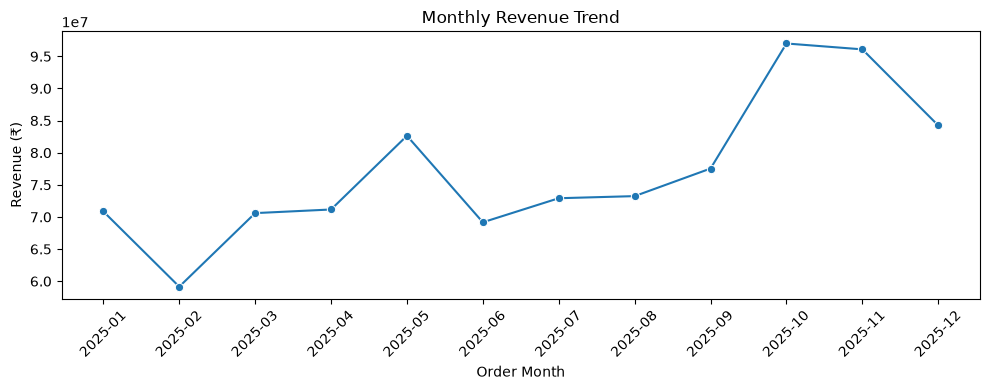

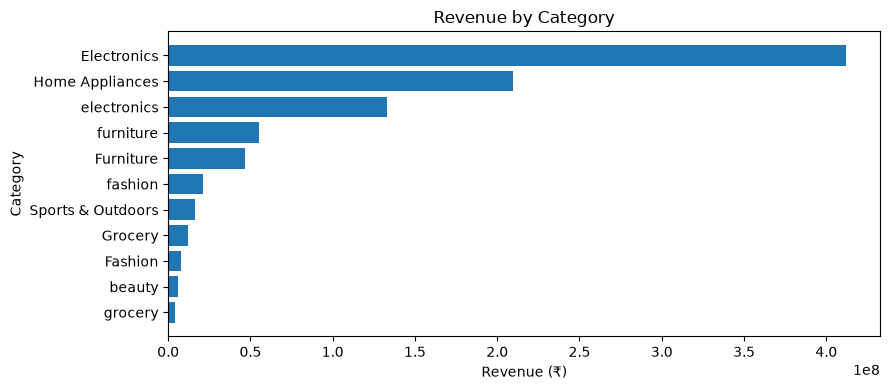

,Region_Name,Revenue,Profit,Orders,Customers,Margin_Pct
3,South,3.042893e+08,93785559.61,24364,3436,30.821179
4,West,2.158271e+08,69333235.01,17073,2591,32.124431
2,North,1.979705e+08,59882407.92,15776,2463,30.248152
1,East,1.070346e+08,30915289.22,8931,1690,28.883449
0,Central,9.945585e+07,28193630.65,8334,1585,28.347885


,Channel_Name,Revenue,Profit,Orders,Margin_Pct,AOV
2,Online,3.898350e+08,1.190771e+08,31804,30.545520,12257.421309
3,Retail Store,2.385538e+08,8.461149e+07,17807,35.468510,13396.632921
1,Marketplace,2.159772e+08,5.515150e+07,18387,25.535796,11746.190038
0,Corporate,8.021133e+07,2.327000e+07,6480,29.010861,12378.291119


In [7]:
fact = fact.merge(products[['Product_ID','Product_Name','Category','Subcategory','Brand']], on='Product_ID', how='left')
fact = fact.merge(regions[['Region_ID','Region_Name','State','City']], on='Region_ID', how='left')
fact = fact.merge(customers[['Customer_ID','Customer_Name','Customer_Segment']], on='Customer_ID', how='left')
fact = fact.merge(channels[['Channel_ID','Channel_Name']], on='Channel_ID', how='left')
fact['Order_Month'] = fact['Order_Date'].dt.to_period('M').astype(str)
fact['Quarter'] = 'Q' + fact['Order_Date'].dt.quarter.astype(str)
fact['Margin_Pct'] = fact['Profit']/fact['Revenue']*100

monthly = fact.groupby('Order_Month').agg(Revenue=('Revenue','sum'), Profit=('Profit','sum'), Orders=('Order_ID','nunique'), Units=('Quantity','sum')).reset_index()
monthly['Revenue_Growth_Pct'] = monthly['Revenue'].pct_change()*100
monthly['Profit_Growth_Pct'] = monthly['Profit'].pct_change()*100

fig, ax = plt.subplots(figsize=(10,4))
sns.lineplot(data=monthly, x='Order_Month', y='Revenue', marker='o', ax=ax)
ax.set_title('Monthly Revenue Trend')
ax.set_xlabel('Order Month'); ax.set_ylabel('Revenue (₹)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

category = fact.groupby('Category').agg(Revenue=('Revenue','sum'),Profit=('Profit','sum')).reset_index()
category['Margin_Pct']=category['Profit']/category['Revenue']*100
fig, ax = plt.subplots(figsize=(9,4))
plot_category = category.sort_values('Revenue', ascending=True)
ax.barh(plot_category['Category'], plot_category['Revenue'])
ax.set_title('Revenue by Category'); ax.set_xlabel('Revenue (₹)'); ax.set_ylabel('Category')
plt.tight_layout(); plt.show()

region = fact.groupby('Region_Name').agg(Revenue=('Revenue','sum'),Profit=('Profit','sum'),Orders=('Order_ID','nunique'),Customers=('Customer_ID','nunique')).reset_index()
region['Margin_Pct']=region['Profit']/region['Revenue']*100
display(region.sort_values('Revenue',ascending=False))

channel = fact.groupby('Channel_Name').agg(Revenue=('Revenue','sum'),Profit=('Profit','sum'),Orders=('Order_ID','nunique')).reset_index()
channel['Margin_Pct']=channel['Profit']/channel['Revenue']*100
channel['AOV']=channel['Revenue']/channel['Orders']
display(channel.sort_values('Revenue',ascending=False))


## 8. Product / Customer / Regional Analysis

In [8]:
product = fact.groupby(['Product_ID','Product_Name','Category']).agg(Revenue=('Revenue','sum'),Cost=('Cost','sum'),Profit=('Profit','sum'),Quantity=('Quantity','sum')).reset_index()
product['Margin_Pct']=product['Profit']/product['Revenue']*100
print('Top products by revenue')
display(product.sort_values('Revenue',ascending=False).head(10))
print('High-revenue / low-margin candidates')
rev_threshold = product['Revenue'].quantile(.75)
display(product[product['Revenue']>=rev_threshold].sort_values('Margin_Pct').head(10))

customer = fact.groupby(['Customer_ID','Customer_Name','Customer_Segment']).agg(Revenue=('Revenue','sum'),Orders=('Order_ID','nunique')).reset_index()
print('Top customers')
display(customer.sort_values('Revenue',ascending=False).head(10))

segment = fact.groupby('Customer_Segment').agg(Revenue=('Revenue','sum'),Orders=('Order_ID','nunique'),Customers=('Customer_ID','nunique')).reset_index()
segment['Revenue_per_Customer']=segment['Revenue']/segment['Customers']
display(segment.sort_values('Revenue',ascending=False))


Top products by revenue


,Product_ID,Product_Name,Category,Revenue,Cost,Profit,Quantity,Margin_Pct
1,P002,NovaBook Pro 16,Electronics,84768637.97,67712000.0,17056637.97,1058,20.121401
0,P001,NovaBook Air 14,Electronics,81575721.80,62544000.0,19031721.80,1303,23.330130
4,P005,SmartView 55 TV,Electronics,61910353.62,41792000.0,20118353.62,1306,32.495944
2,P003,WorkMate 15 Laptop,Electronics,61801570.65,44967000.0,16834570.65,1153,27.239713
8,P009,AirCool 1.5T AC,Home Appliances,57471271.01,41536000.0,15935271.01,1298,27.727368
3,P004,SmartView 43 TV,Electronics,54048063.05,37200000.0,16848063.05,1550,31.172372
50,P051,NovaPhone Max 5G,Electronics,44689898.63,31037000.0,13652898.63,1514,30.550301
49,P050,NovaPhone 5G,electronics,40858160.58,27958500.0,12899660.58,2071,31.571809
48,P049,NovaTab 10,electronics,35771839.36,24800000.0,10971839.36,1600,30.671723
11,P012,WashSmart 7kg Washer,Home Appliances,32000085.39,22869000.0,9131085.39,1089,28.534566


High-revenue / low-margin candidates


,Product_ID,Product_Name,Category,Revenue,Cost,Profit,Quantity,Margin_Pct
1,P002,NovaBook Pro 16,Electronics,84768637.97,67712000.0,17056637.97,1058,20.121401
0,P001,NovaBook Air 14,Electronics,81575721.80,62544000.0,19031721.80,1303,23.330130
2,P003,WorkMate 15 Laptop,Electronics,61801570.65,44967000.0,16834570.65,1153,27.239713
8,P009,AirCool 1.5T AC,Home Appliances,57471271.01,41536000.0,15935271.01,1298,27.727368
11,P012,WashSmart 7kg Washer,Home Appliances,32000085.39,22869000.0,9131085.39,1089,28.534566
12,P013,HeatWave Microwave,Home Appliances,15412845.09,10941000.0,4471845.09,1563,29.013755
9,P010,BreezePlus Cooler,Home Appliances,19772686.35,13872000.0,5900686.35,1632,29.842613
66,P067,Robot Floor Cleaner,Home Appliances,18915783.47,13154400.0,5761383.47,783,30.458075
50,P051,NovaPhone Max 5G,Electronics,44689898.63,31037000.0,13652898.63,1514,30.550301
48,P049,NovaTab 10,electronics,35771839.36,24800000.0,10971839.36,1600,30.671723


Top customers


,Customer_ID,Customer_Name,Customer_Segment,Revenue,Orders
7314,C07450,Priya Das,High Value,870098.92,32
7146,C07277,Isha Joshi,High Value,856102.16,36
4724,C04809,Rohan Kulkarni,High Value,838045.21,29
5806,C05907,Sai Das,High Value,834607.49,33
2092,C02124,Nandini Reddy,High Value,834347.45,28
1077,C01090,Varun Roy,High Value,809626.62,37
1031,C01044,Keerthi Naidu,High Value,801862.42,39
6299,C06407,Keerthi Reddy,High Value,792109.49,27
569,C00577,Manish Gupta,High Value,778415.25,35
6894,C07018,Simran Jain,High Value,768131.98,22


,Customer_Segment,Revenue,Orders,Customers,Revenue_per_Customer
0,High Value,5.569904e+08,33893,1869,298015.171905
2,Loyal,3.091168e+08,35375,3512,88017.302862
4,Regular,4.152080e+07,3784,1088,38162.497555
3,Occasional,1.244787e+07,1064,532,23398.255263
1,Low Value,4.501599e+06,362,362,12435.357265


## 9. Outlier Analysis

In [9]:
order_values = fact.groupby('Order_ID')['Revenue'].sum()
q1,q3 = order_values.quantile([0.25,0.75])
iqr=q3-q1
upper=q3+1.5*iqr
outliers=order_values[order_values>upper]
print(f'Order-value Q1: ₹{q1:,.0f}, Q3: ₹{q3:,.0f}, IQR: ₹{iqr:,.0f}')
print(f'Upper outlier threshold: ₹{upper:,.0f}')
print(f'Orders above threshold: {len(outliers):,}')
print('Outliers are retained when they have valid keys and financial logic; they are investigated rather than automatically deleted.')


Order-value Q1: ₹1,597, Q3: ₹10,205, IQR: ₹8,608
Upper outlier threshold: ₹23,117
Orders above threshold: 10,175
Outliers are retained when they have valid keys and financial logic; they are investigated rather than automatically deleted.


## 10. Business Insights

In [10]:
strongest_month = monthly.loc[monthly['Revenue'].idxmax()]
lowest_margin_region = region.loc[region['Margin_Pct'].idxmin()]
top_product = product.loc[product['Revenue'].idxmax()]
low_margin_rev = product[product['Revenue']>product['Revenue'].quantile(.75)].sort_values('Margin_Pct').iloc[0]
print(f'Finding: {strongest_month.Order_Month} is the strongest month by revenue at ₹{strongest_month.Revenue:,.0f}.')
print(f'Finding: {lowest_margin_region.Region_Name} has the lowest regional margin at {lowest_margin_region.Margin_Pct:.1f}%.')
print(f'Finding: {top_product.Product_Name} is the top product by revenue at ₹{top_product.Revenue:,.0f}.')
print(f'Finding: {low_margin_rev.Product_Name} combines high revenue with a relatively weak {low_margin_rev.Margin_Pct:.1f}% margin.')


Finding: 2025-10 is the strongest month by revenue at ₹96,997,848.
Finding: Central has the lowest regional margin at 28.3%.
Finding: NovaBook Pro 16 is the top product by revenue at ₹84,768,638.
Finding: NovaBook Pro 16 combines high revenue with a relatively weak 20.1% margin.


## 11. Validation

In [11]:
# Core reconciliation checks against saved analytical values.
expected = pd.read_csv(PROJECT_ROOT/'qa'/'cross_validation.csv') if (PROJECT_ROOT/'qa'/'cross_validation.csv').exists() else None
print('Cleaned fact rows:', len(fact))
assert fact['Order_ID'].is_unique
assert fact['Revenue'].ge(0).all()
assert np.isfinite(fact['Profit']).all()
print('Notebook validation checks passed.')


Cleaned fact rows: 74478
Notebook validation checks passed.
